In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util_machine_learning as uml
import utils.visualization as vis

import test_code.dfield_approach_elastix.constants as cts
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

from scipy import stats

from features_loader import FeaturesLoader

np.set_printoptions(precision=4)

matching_ids = pil.get_matching_ids()
EXCLUDED_PATIENTS = pil.EXCLUDED_PATIENTS


matching_ids = [x for x in matching_ids if x not in EXCLUDED_PATIENTS]

SERVER: False


# Top similarity table

In [2]:
reader_hunt3 = FeaturesLoader(pil.get_matching_ids(), hunt=3)
reader_hunt4 = FeaturesLoader(pil.get_matching_ids(), hunt=4)

sim_metric= "ssim"
top1 = []
top3 = []
top5 = []
top10 = []

similarity_table = np.zeros((len(matching_ids), 2))
c = 0
for i, id in enumerate(tqdm(matching_ids)):
    hunt3_sim_df = reader_hunt3.get_sorted_similarity_table(id, sim_metric, nb_images=20, exclude_ids=EXCLUDED_PATIENTS)
    hunt4_sim_df = reader_hunt4.get_sorted_similarity_table(id, sim_metric, nb_images=-1, exclude_ids=EXCLUDED_PATIENTS)

    best_id_hunt3 = hunt3_sim_df["id"].tolist()
    best_id_hunt4 = hunt4_sim_df["id"].tolist()

    top1.append(best_id_hunt3[0] == best_id_hunt4[0])
    top3.append(best_id_hunt3[0] in best_id_hunt4[:3])
    top5.append(best_id_hunt3[0] in best_id_hunt4[:5])
    top10.append(best_id_hunt3[0] in best_id_hunt4[:15])

    similarity_table[i, 0] = hunt3_sim_df[sim_metric].iloc[0]
    similarity_table[i, 1] = hunt4_sim_df[sim_metric].iloc[best_id_hunt4.index(best_id_hunt3[0])]
    # similarity_table[i, 1] = hunt4_sim_df[sim_metric].iloc[-1]


res_top1 = sum(top1)
res_top3 = sum(top3)
res_top5 = sum(top5)
res_top10 = sum(top10)

similarity_df = pd.DataFrame(similarity_table, columns=["HUNT3", "HUNT4"])

    

# top1 470 67
# top3 647 92
# top5 679 97
# top10 693 99

100%|██████████| 698/698 [00:03<00:00, 206.30it/s]


In [3]:
def dislay_boxplot_df(df, tytle="", melted=False, figsize=(20, 6), palette="pastel"):
    if not melted:
        df_melted = df.melt(var_name='HUNT', value_name='Similarity')
    else:
        df_melted = df
    print(df_melted.head())
    # Crear el boxplot con jitter
    plt.figure(figsize=figsize)
    sns.boxplot(x='HUNT', y='Similarity', hue='HUNT', data=df_melted, palette=palette)
    sns.stripplot(x='HUNT', y='Similarity', data=df_melted, color='black', alpha=0.3, jitter=True, size=1)
    plt.title(tytle)
    plt.ylim(0, 1)
    plt.show()

    HUNT  Similarity
0  HUNT3    0.836787
1  HUNT3    0.814502
2  HUNT3    0.812329
3  HUNT3    0.850280
4  HUNT3    0.832757


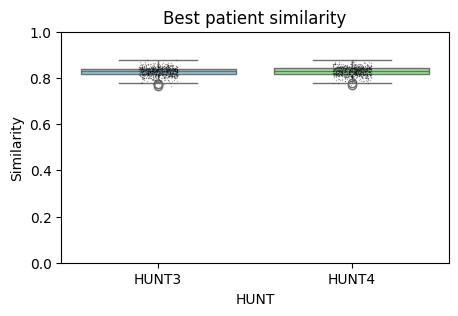

top1 470 67.0
top3 647 93.0
top5 679 97.0
top10 698 100.0


In [4]:
custom_palette = {
    'HUNT3': 'skyblue',
    'HUNT4': 'lightgreen'
}

dislay_boxplot_df(similarity_df, tytle="Best patient similarity", melted=False, figsize=(5, 3), palette=custom_palette)

print("top1", res_top1, np.round(res_top1/len(matching_ids)*100))
print("top3", res_top3, np.round(res_top3/len(matching_ids)*100))
print("top5", res_top5, np.round(res_top5/len(matching_ids)*100))
print("top10", res_top10, np.round(res_top10/len(matching_ids)*100))